## Tree-based models building (Hourly)

Predicts hourly `actual_consumption` 1-24 hours ahead - direct multi-step: one model per horizon `h=1..24`, same `X` anchored to "this hour", only the target shifts forward. 3 model types compared (XGBoost, CatBoost, LightGBM - RandomForest not used here), best one picked per horizon.

**Steps:**

Model Building :

1. Load data, select features, build lags
2. Split train (2019-22) / val (2023) / test (2024)
3. Build the 24 shifted targets (`h=1`=this hour ... `h=24`=23 hours ahead)
4. CV-tune each model type per horizon → pick the best per horizon (by validation MAE) → refit on train+val → evaluate on test
5. Export 2024 predictions to CSV

In [53]:
import pandas as pd
import numpy as np

# plot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import seaborn as sns

# CV
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# tree models
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb

# Model Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [54]:
data_hourly = pd.read_csv("../../../data/final/data_hourly.csv")
data_hourly.head(5)

,Unnamed: 0,date_from,date_to,date_from_utc,actual_consumption,actual_consumption_incl_pumped,hydro_pumped_storage,residual_load,month,day_of_week_raw,...,ipi_ei_yoy,ipi_ei_staleness_days,ipi_ei_ref_month,ipi_ei_release_date,ipi_ei_release_source,hdd,shortwave_radiation,wind_speed_10m,precipitation,is_day
0,0,2019-01-01 00:00:00,2019-01-01 01:00:00,2018-12-31 23:00:00,43273.75,44546.75,1273.00,19825.50,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,11.659001,0.0,15.731302,0.022924,0
1,1,2019-01-01 01:00:00,2019-01-01 02:00:00,2019-01-01 00:00:00,41631.25,43042.00,1410.75,16465.75,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,11.340103,0.0,16.552715,0.037055,0
2,2,2019-01-01 02:00:00,2019-01-01 03:00:00,2019-01-01 01:00:00,40085.00,42561.75,2476.75,14456.25,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,11.306928,0.0,18.065750,0.015296,0
3,3,2019-01-01 03:00:00,2019-01-01 04:00:00,2019-01-01 02:00:00,39269.75,42554.25,3284.50,12101.50,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,11.485899,0.0,19.236869,0.022635,0
4,4,2019-01-01 04:00:00,2019-01-01 05:00:00,2019-01-01 03:00:00,39032.75,42748.50,3715.75,10134.25,1,1,...,-3.5681,62,2018-10,2018-12-10,rule,11.571205,0.0,20.909836,0.015630,0


### Column Selection

- Generations Features
    - Remove generations (same as daily)
- Sunlight
    - No `daylight_duration` column here (unlike daily) - sunlight already captured directly via `shortwave_radiation` + `is_day`
- Prices
    - `gas_price_eu_usd` and `day_ahead_price` are highly correlated (same relationship as daily)
    - Remove `gas_price_eu_usd`, keep `day_ahead_price` - already hourly-granular, so no need for the mean/min/max aggregation daily used

In [55]:
y = ['actual_consumption']

time_date = ['date_from', 'date_from_utc', 'month', 'day_of_week_raw', 'is_holiday',
            'is_weekday', 'weighted_regional_holiday', 'weighted_school_holiday',
            'is_bridge_day', 'is_christmas_new_year', 'is_dst', 'is_dst_transition_day']


# generations = ['generation_wind_onshore', 'generation_wind_offshore',
#     'generation_solar', 'generation_lignite', 'generation_hard_coal',
#     'generation_natural_gas', 'generation_nuclear']


prices = ['day_ahead_price']

# past 7 days' average price (excludes the current hour itself, so it's a separate
# "recent price environment" signal rather than just smoothing the current value)
data_hourly['day_ahead_price_7d'] = (
    data_hourly['day_ahead_price'].shift(1).rolling(24 * 7).mean()
)
prices = prices + ['day_ahead_price_7d']

weather_columns = [
    'hdd', 'shortwave_radiation',
    'wind_speed_10m', 'precipitation', 'is_day'
]


# yearly harmonics (same 3 kept as daily) + daily/intraday harmonics (new for hourly -
# not yet reduced, correlation heatmap below will help decide if some can be dropped)
fourier_columns = [
    'sin_y1', 'cos_y1', 'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3',
    'sin_d1', 'cos_d1', 'sin_d2', 'cos_d2', 'sin_d3', 'cos_d3',
    'sin_d4', 'cos_d4', 'sin_d5', 'cos_d5', 'sin_d6', 'cos_d6',
]

others = ['oxcgrt_stringency', 'ipi_ei_level', 'industrial_confidence',
          'solar_capacity_mw']

### Add solar_capacity_mw * shortwave_radiation

In [56]:
data_hourly["solar_radiation_combi"] = data_hourly["solar_capacity_mw"] * data_hourly["shortwave_radiation"]

if "solar_radiation_combi" not in others:
    others = others + ["solar_radiation_combi"]

others.remove("solar_capacity_mw")
weather_columns.remove("shortwave_radiation")

In [57]:
data_hourly.columns

Index(['Unnamed: 0', 'date_from', 'date_to', 'date_from_utc',
       'actual_consumption', 'actual_consumption_incl_pumped',
       'hydro_pumped_storage', 'residual_load', 'month', 'day_of_week_raw',
       'day_of_week', 'is_holiday', 'is_weekday', 'weighted_regional_holiday',
       'weighted_school_holiday', 'is_bridge_day', 'is_christmas_new_year',
       'is_dst', 'is_dst_transition_day', 'gas_price_eu_usd',
       'industrial_confidence', 'day_ahead_price', 'sin_y1', 'cos_y1',
       'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3', 'sin_y4', 'cos_y4', 'sin_y5',
       'cos_y5', 'sin_y6', 'cos_y6', 'sin_y7', 'cos_y7', 'sin_y8', 'cos_y8',
       'sin_y9', 'cos_y9', 'sin_y10', 'cos_y10', 'sin_d1', 'cos_d1', 'sin_d2',
       'cos_d2', 'sin_d3', 'cos_d3', 'sin_d4', 'cos_d4', 'sin_d5', 'cos_d5',
       'sin_d6', 'cos_d6', 'generation_wind_onshore',
       'generation_wind_offshore', 'generation_solar', 'generation_lignite',
       'generation_hard_coal', 'generation_natural_gas', 'generation_n

### Lag Selection

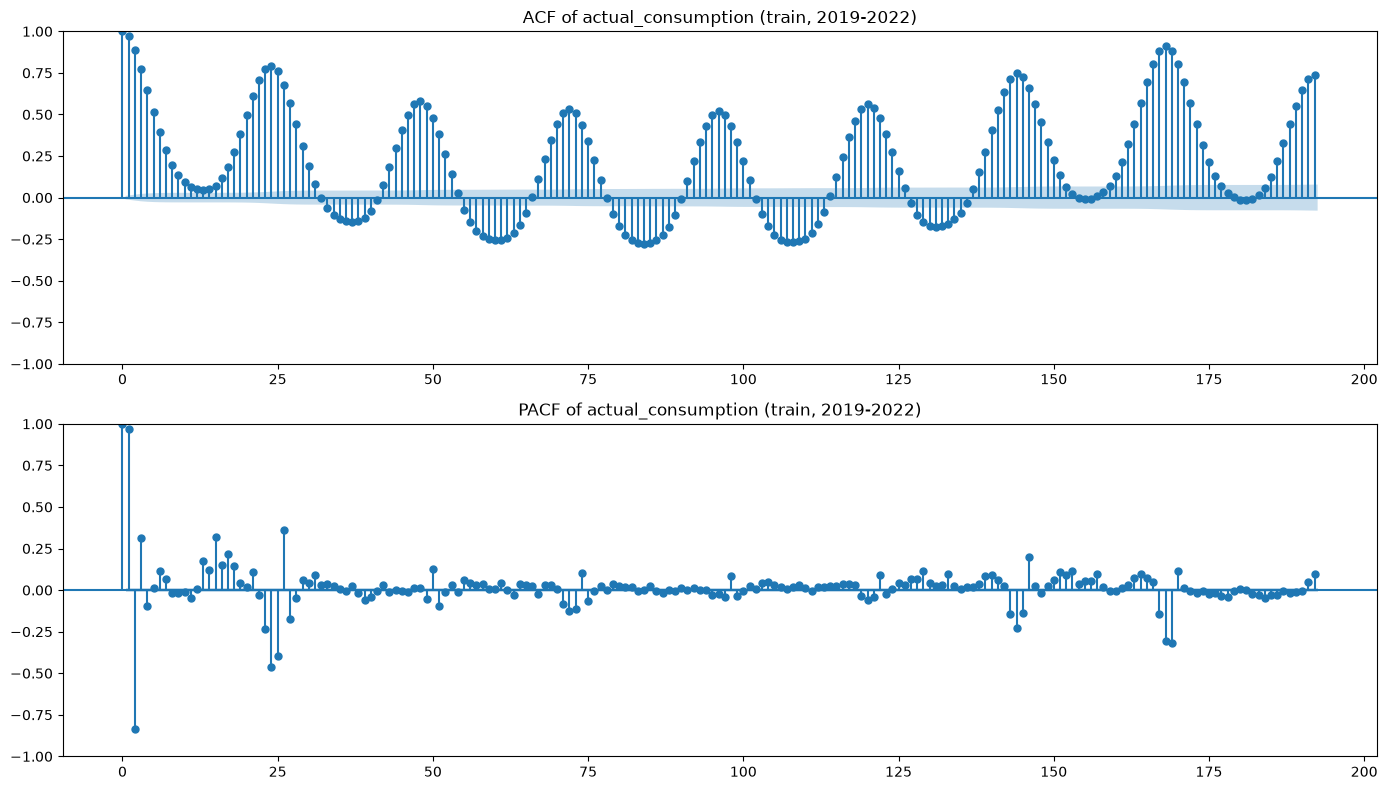

In [58]:
### ACF, PACF

subset = data_hourly.query("date_from >= '2019-01-01' and date_from <= '2022-12-31'")

n_lags = 192  # 8 days: enough to see the daily (24h) cycle decay plus the start of a weekly (168h) echo

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(subset.actual_consumption, lags=n_lags, ax=axes[0])
axes[0].set_title("ACF of actual_consumption (train, 2019-2022)")

plot_pacf(subset.actual_consumption, lags=n_lags, method="ywm", ax=axes[1])
axes[1].set_title("PACF of actual_consumption (train, 2019-2022)")

plt.tight_layout()
plt.show()

In [59]:
### Add lags into dataset
# Preliminary pick based on typical hourly-electricity structure (previous hour, same
# hour yesterday, same hour last week) - adjust once we've inspected the PACF plot above

for lag in [1, 24, 48, 168]:
    data_hourly[f"lag_{lag}"] = data_hourly["actual_consumption"].shift(lag)

lag_cols = ["lag_1", "lag_24", "lag_48", "lag_168"]

time_date.extend(lag_cols)

In [60]:
data_hourly = data_hourly.loc[:, y + time_date + prices + weather_columns
                + fourier_columns + others]

data_hourly.head()

,actual_consumption,date_from,date_from_utc,month,day_of_week_raw,is_holiday,is_weekday,weighted_regional_holiday,weighted_school_holiday,is_bridge_day,...,sin_d4,cos_d4,sin_d5,cos_d5,sin_d6,cos_d6,oxcgrt_stringency,ipi_ei_level,industrial_confidence,solar_radiation_combi
0,43273.75,2019-01-01 00:00:00,2018-12-31 23:00:00,1,1,True,True,0.0,0.448877,False,...,0.000000e+00,1.0,0.000000,1.000000,0.000000e+00,1.000000e+00,0.0,100.0,3.8,0.0
1,41631.25,2019-01-01 01:00:00,2019-01-01 00:00:00,1,1,True,True,0.0,0.448877,False,...,8.660254e-01,0.5,0.965926,0.258819,1.000000e+00,6.123234e-17,0.0,100.0,3.8,0.0
2,40085.00,2019-01-01 02:00:00,2019-01-01 01:00:00,1,1,True,True,0.0,0.448877,False,...,8.660254e-01,-0.5,0.500000,-0.866025,1.224647e-16,-1.000000e+00,0.0,100.0,3.8,0.0
3,39269.75,2019-01-01 03:00:00,2019-01-01 02:00:00,1,1,True,True,0.0,0.448877,False,...,1.224647e-16,-1.0,-0.707107,-0.707107,-1.000000e+00,-1.836970e-16,0.0,100.0,3.8,0.0
4,39032.75,2019-01-01 04:00:00,2019-01-01 03:00:00,1,1,True,True,0.0,0.448877,False,...,-8.660254e-01,-0.5,-0.866025,0.500000,-2.449294e-16,1.000000e+00,0.0,100.0,3.8,0.0


In [61]:
data_hourly.columns

Index(['actual_consumption', 'date_from', 'date_from_utc', 'month',
       'day_of_week_raw', 'is_holiday', 'is_weekday',
       'weighted_regional_holiday', 'weighted_school_holiday', 'is_bridge_day',
       'is_christmas_new_year', 'is_dst', 'is_dst_transition_day', 'lag_1',
       'lag_24', 'lag_48', 'lag_168', 'day_ahead_price', 'day_ahead_price_7d',
       'hdd', 'wind_speed_10m', 'precipitation', 'is_day', 'sin_y1', 'cos_y1',
       'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3', 'sin_d1', 'cos_d1', 'sin_d2',
       'cos_d2', 'sin_d3', 'cos_d3', 'sin_d4', 'cos_d4', 'sin_d5', 'cos_d5',
       'sin_d6', 'cos_d6', 'oxcgrt_stringency', 'ipi_ei_level',
       'industrial_confidence', 'solar_radiation_combi'],
      dtype='str')

In [62]:
# Training set, Validation set, Testing set

data_hourly['date_from'] = pd.to_datetime(data_hourly['date_from'])
data_hourly['date_from_utc'] = pd.to_datetime(data_hourly['date_from_utc'])

# sort by UTC - uniform 1-hour spacing, no DST duplicate/gap hour, so the lag/target
# shift()s above are stepping through physically consecutive hours
data_hourly = data_hourly.sort_values('date_from_utc').reset_index(drop=True)

# year masks use German local time (date_from) - "2024" means German wall-clock 2024,
# which starts at UTC 2023-12-31 23:00 in winter time, not UTC 2024-01-01 00:00
train_mask = data_hourly['date_from'].dt.year <= 2022
val_mask   = data_hourly['date_from'].dt.year == 2023
test_mask  = data_hourly['date_from'].dt.year == 2024

feature_cols = [c for c in data_hourly.columns if c not in ['actual_consumption', 'date_from', 'date_from_utc']]

X_train, y_train = data_hourly.loc[train_mask, feature_cols], data_hourly.loc[train_mask, 'actual_consumption']
X_val,   y_val   = data_hourly.loc[val_mask, feature_cols],   data_hourly.loc[val_mask, 'actual_consumption']
X_test,  y_test  = data_hourly.loc[test_mask, feature_cols],  data_hourly.loc[test_mask, 'actual_consumption']

print(f"train: {X_train.shape}, {y_train.index.min()}..{y_train.index.max()}")
print(f"val:   {X_val.shape}, {data_hourly.loc[val_mask, 'date_from'].min()}..{data_hourly.loc[val_mask, 'date_from'].max()}")
print(f"test:  {X_test.shape}, {data_hourly.loc[test_mask, 'date_from'].min()}..{data_hourly.loc[test_mask, 'date_from'].max()}")

train: (35064, 42), 0..35063
val:   (8760, 42), 2023-01-01 00:00:00..2023-12-31 23:00:00
test:  (8784, 42), 2024-01-01 00:00:00..2024-12-31 23:00:00


In [63]:
X_train.head()

,month,day_of_week_raw,is_holiday,is_weekday,weighted_regional_holiday,weighted_school_holiday,is_bridge_day,is_christmas_new_year,is_dst,is_dst_transition_day,...,sin_d4,cos_d4,sin_d5,cos_d5,sin_d6,cos_d6,oxcgrt_stringency,ipi_ei_level,industrial_confidence,solar_radiation_combi
0,1,1,True,True,0.0,0.448877,False,True,False,False,...,0.000000e+00,1.0,0.000000,1.000000,0.000000e+00,1.000000e+00,0.0,100.0,3.8,0.0
1,1,1,True,True,0.0,0.448877,False,True,False,False,...,8.660254e-01,0.5,0.965926,0.258819,1.000000e+00,6.123234e-17,0.0,100.0,3.8,0.0
2,1,1,True,True,0.0,0.448877,False,True,False,False,...,8.660254e-01,-0.5,0.500000,-0.866025,1.224647e-16,-1.000000e+00,0.0,100.0,3.8,0.0
3,1,1,True,True,0.0,0.448877,False,True,False,False,...,1.224647e-16,-1.0,-0.707107,-0.707107,-1.000000e+00,-1.836970e-16,0.0,100.0,3.8,0.0
4,1,1,True,True,0.0,0.448877,False,True,False,False,...,-8.660254e-01,-0.5,-0.866025,0.500000,-2.449294e-16,1.000000e+00,0.0,100.0,3.8,0.0


In [64]:
X_train.columns

Index(['month', 'day_of_week_raw', 'is_holiday', 'is_weekday',
       'weighted_regional_holiday', 'weighted_school_holiday', 'is_bridge_day',
       'is_christmas_new_year', 'is_dst', 'is_dst_transition_day', 'lag_1',
       'lag_24', 'lag_48', 'lag_168', 'day_ahead_price', 'day_ahead_price_7d',
       'hdd', 'wind_speed_10m', 'precipitation', 'is_day', 'sin_y1', 'cos_y1',
       'sin_y2', 'cos_y2', 'sin_y3', 'cos_y3', 'sin_d1', 'cos_d1', 'sin_d2',
       'cos_d2', 'sin_d3', 'cos_d3', 'sin_d4', 'cos_d4', 'sin_d5', 'cos_d5',
       'sin_d6', 'cos_d6', 'oxcgrt_stringency', 'ipi_ei_level',
       'industrial_confidence', 'solar_radiation_combi'],
      dtype='str')

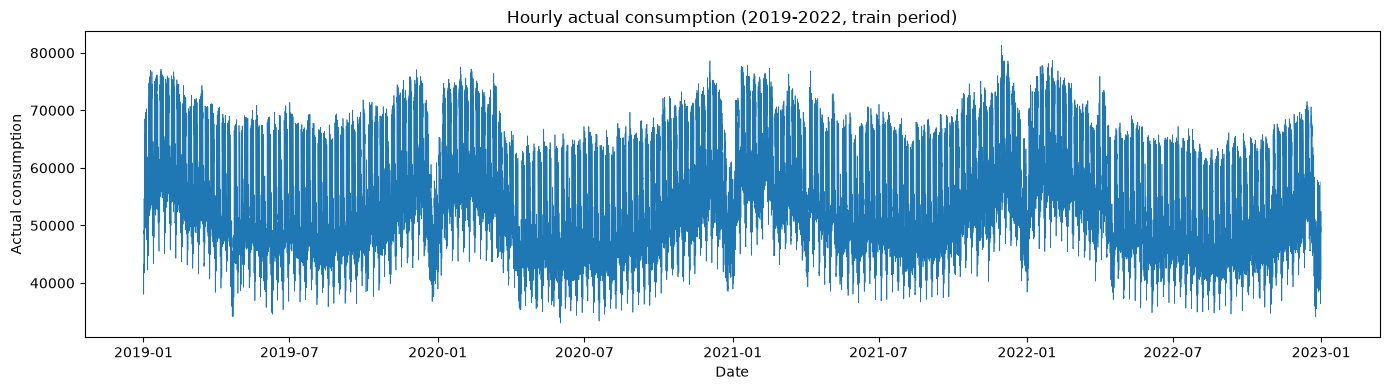

In [65]:
### Time-series overview

plt.figure(figsize=(14, 4))
plt.plot(
    data_hourly.loc[train_mask, 'date_from'],
    data_hourly.loc[train_mask, 'actual_consumption'],
    linewidth=0.5,
)
plt.xlabel("Date")
plt.ylabel("Actual consumption")
plt.title("Hourly actual consumption (2019-2022, train period)")
plt.tight_layout()
plt.show()

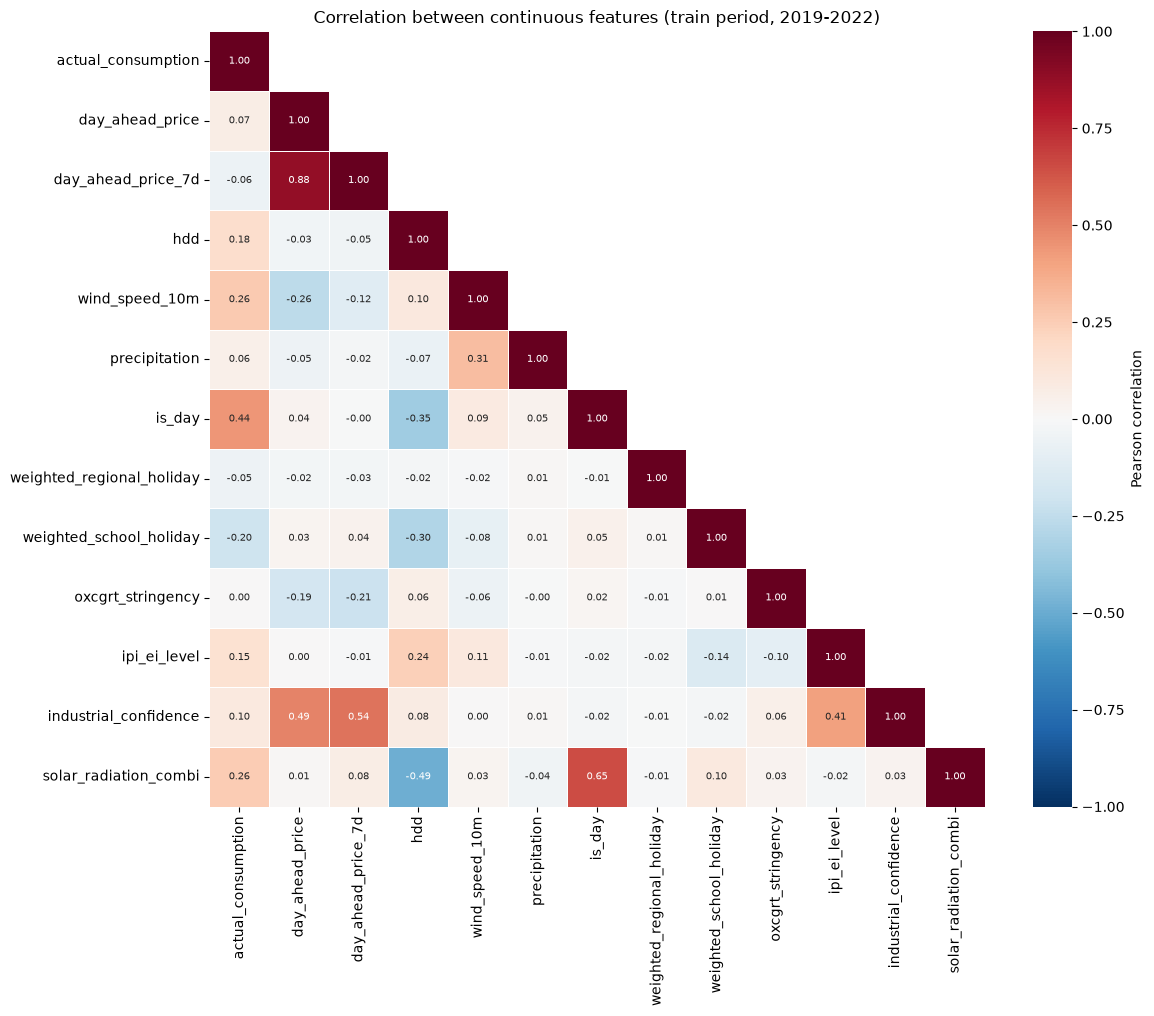

In [66]:
# only the continuous columns - drop booleans (is_holiday, ...), ordinal/categorical
# (month, day_of_week_raw), date_from/date_from_utc, and the fourier sin/cos terms
# (deterministic calendar encodings, not informative here and would clutter the matrix)
continuous_cols = (
    prices + weather_columns
    + ['weighted_regional_holiday', 'weighted_school_holiday']
    + others
)

# computed on the train period only, so the plot isn't informed by val/test
corr = data_hourly.loc[train_mask, ['actual_consumption'] + continuous_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    square=True, linewidths=0.5, cbar_kws={'label': 'Pearson correlation'}, ax=ax
)
ax.set_title('Correlation between continuous features (train period, 2019-2022)')
plt.tight_layout()
plt.show()

## Model Building

Target prep, per-model CV tuning, final model selection, export.

### Multi-step Forecasting (this hour + 23 hours ahead) - Target Preparation

Same design as the daily model, just `max_horizon = 24` instead of 7:
- **h=1 = this hour** (nowcast - today's/this hour's X predicts this hour's Y)
- **h=2..24 = 1..23 hours ahead** (true forecast - X is unchanged (still this hour's values, including `lag_1`/`lag_24`/`lag_168`), but the target moves forward)
- **X stays exactly the same** (`X_train`/`X_val`/`X_test` above) for every h - anchored to "this hour".
- **target_h** = `actual_consumption` shifted `(h-1)` hours forward (`shift(-(h-1))`). h=1 means no shift (identical to the un-shifted series).
- **Tail NaNs**: the last `(h-1)` rows of the whole series have no answer yet that far ahead, dropped per-horizon before training/evaluating that horizon.

One shot over a given hour's row then gives 24 predictions (h=1..24) = one full day ahead, hour by hour.

In [67]:
# Build the shifted targets - h=1 is "this hour" (no shift), h=2..24 are 1..23 hours ahead

max_horizon = 24

targets = {}
for h in range(1, max_horizon + 1):
    targets[h] = data_hourly['actual_consumption'].shift(-(h - 1))

targets[1].equals(data_hourly['actual_consumption'])  # sanity check: h=1 should be identical to the un-shifted series

True

In [68]:
# Split each horizon's target with the same train/val/test masks as the single-hour model,
# dropping rows where the shifted target is NaN (tail of the whole series)

X_train_h, X_val_h, X_test_h = {}, {}, {}
y_train_h, y_val_h, y_test_h = {}, {}, {}

for h in range(1, max_horizon + 1):
    valid = targets[h].notna()

    y_train_h[h] = targets[h][train_mask & valid]
    y_val_h[h]   = targets[h][val_mask & valid]
    y_test_h[h]  = targets[h][test_mask & valid]

    X_train_h[h] = X_train.loc[y_train_h[h].index]
    X_val_h[h]   = X_val.loc[y_val_h[h].index]
    X_test_h[h]  = X_test.loc[y_test_h[h].index]

for h in range(1, max_horizon + 1):
    print(f"h={h}: train={X_train_h[h].shape}, val={X_val_h[h].shape}, test={X_test_h[h].shape}")

h=1: train=(35064, 42), val=(8760, 42), test=(8784, 42)
h=2: train=(35064, 42), val=(8760, 42), test=(8783, 42)
h=3: train=(35064, 42), val=(8760, 42), test=(8782, 42)
h=4: train=(35064, 42), val=(8760, 42), test=(8781, 42)
h=5: train=(35064, 42), val=(8760, 42), test=(8780, 42)
h=6: train=(35064, 42), val=(8760, 42), test=(8779, 42)
h=7: train=(35064, 42), val=(8760, 42), test=(8778, 42)
h=8: train=(35064, 42), val=(8760, 42), test=(8777, 42)
h=9: train=(35064, 42), val=(8760, 42), test=(8776, 42)
h=10: train=(35064, 42), val=(8760, 42), test=(8775, 42)
h=11: train=(35064, 42), val=(8760, 42), test=(8774, 42)
h=12: train=(35064, 42), val=(8760, 42), test=(8773, 42)
h=13: train=(35064, 42), val=(8760, 42), test=(8772, 42)
h=14: train=(35064, 42), val=(8760, 42), test=(8771, 42)
h=15: train=(35064, 42), val=(8760, 42), test=(8770, 42)
h=16: train=(35064, 42), val=(8760, 42), test=(8769, 42)
h=17: train=(35064, 42), val=(8760, 42), test=(8768, 42)
h=18: train=(35064, 42), val=(8760, 42),

In [69]:
# Evaluation function

results = []

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = (abs((y_true - y_pred) / y_true)).mean() * 100
    print(f"{name:25s} MAE={mae:>12,.0f}  RMSE={rmse:>12,.0f}  MAPE={mape:5.2f}%")
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "MAPE": mape})

### Multi-step XGBoost - CV hyperparameter tuning (per horizon)

- One `GridSearchCV` per horizon `h` (h=1..24, i.e. this hour + 23 hours ahead), searched only on that horizon's `X_train_h[h]` / `y_train_h[h]`
- `TimeSeriesSplit` instead of plain K-Fold, same reasoning as daily
- Same `param_grid` as the daily model - note this is a much bigger job here: 24 horizons instead of 7, and hourly rows (~24x more rows than daily) make every individual fit slower too

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

In [ ]:
# edit this to change what gets searched
param_grid = {
    "max_depth": [3, 5, 7],
    "n_estimators": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_weight": [1, 5, 10],
}

xgb_models_h = {}
best_params_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=xgb.XGBRegressor(random_state=42, n_jobs=1),
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    xgb_models_h[h] = search.best_estimator_
    best_params_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val)

for h in range(1, max_horizon + 1):
    model = xgb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"XGBoost h={h} - val")
    

### Multi-step CatBoost - CV hyperparameter tuning + per-horizon evaluation

Same structure as XGBoost above, h=1..24, same `param_grid_cb` as daily.

In [ ]:
# edit this to change what gets searched
param_grid_cb = {
    "depth": [3, 5, 7],
    "iterations": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "l2_leaf_reg": [1, 5, 10],
}

cb_models_h = {}
best_params_cb_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=CatBoostRegressor(random_state=42, verbose=False, thread_count=1),
        param_grid=param_grid_cb,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    cb_models_h[h] = search.best_estimator_
    best_params_cb_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val)

for h in range(1, max_horizon + 1):
    model = cb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"CatBoost h={h} - val")

### Multi-step LightGBM - CV hyperparameter tuning + per-horizon evaluation

Same structure again, h=1..24, same `param_grid_lgb` as daily.

In [ ]:
# edit this to change what gets searched
param_grid_lgb = {
    "num_leaves": [15, 31, 63],
    "n_estimators": [200, 500, 800],
    "learning_rate": [0.01, 0.05, 0.1],
    "min_child_samples": [10, 20, 40],
}

lgb_models_h = {}
best_params_lgb_h = {}

for h in range(1, max_horizon + 1):
    search = GridSearchCV(
        estimator=lgb.LGBMRegressor(random_state=42, n_jobs=1, verbose=-1),
        param_grid=param_grid_lgb,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )
    search.fit(X_train_h[h], y_train_h[h])

    lgb_models_h[h] = search.best_estimator_
    best_params_lgb_h[h] = search.best_params_

    print(f"h={h}  best_params={search.best_params_}")

In [ ]:
# Per-horizon evaluation - each horizon prints/records its own MAE, RMSE, MAPE (val)

for h in range(1, max_horizon + 1):
    model = lgb_models_h[h]
    evaluate(y_val_h[h], model.predict(X_val_h[h]), f"LightGBM h={h} - val")

### Final per-horizon models

Best model + CV params per h, picked by hand from the per-model validation MAE printed above (CatBoost, XGBoost, LightGBM only - RandomForest wasn't tuned here). Refit on train+val (2019-2023), evaluated once on test (2024). `best_model_config` (below) is also saved to `src/results/tree-based/best_model_config_hourly.json` right after it's defined - `run_tree_based.py` reads that file instead of hand-copying this dict, so there's one place for this choice, not two that can drift apart:

| h | model | params |
|---|---|---|
| 1 | CatBoost | `depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.1` |
| 2 | LightGBM | `learning_rate=0.05, min_child_samples=40, n_estimators=800, num_leaves=31` |
| 3 | CatBoost | `depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.05` |
| 4 | CatBoost | `depth=7, iterations=800, l2_leaf_reg=5, learning_rate=0.05` |
| 5 | CatBoost | `depth=7, iterations=800, l2_leaf_reg=5, learning_rate=0.05` |
| 6 | CatBoost | `depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.05` |
| 7 | CatBoost | `depth=5, iterations=500, l2_leaf_reg=10, learning_rate=0.1` |
| 8 | XGBoost | `learning_rate=0.1, max_depth=5, min_child_weight=10, n_estimators=200` |
| 9 | XGBoost | `learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=800` |
| 10 | XGBoost | `learning_rate=0.05, max_depth=5, min_child_weight=10, n_estimators=200` |
| 11 | XGBoost | `learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800` |
| 12 | XGBoost | `learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800` |
| 13 | XGBoost | `learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800` |
| 14 | LightGBM | `learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=63` |
| 15 | XGBoost | `learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=800` |
| 16 | LightGBM | `learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=31` |
| 17 | LightGBM | `learning_rate=0.01, min_child_samples=10, n_estimators=800, num_leaves=63` |
| 18 | LightGBM | `learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=31` |
| 19 | LightGBM | `learning_rate=0.01, min_child_samples=40, n_estimators=800, num_leaves=31` |
| 20 | LightGBM | `learning_rate=0.05, min_child_samples=40, n_estimators=500, num_leaves=15` |
| 21 | CatBoost | `depth=5, iterations=800, l2_leaf_reg=5, learning_rate=0.05` |
| 22 | CatBoost | `depth=7, iterations=500, l2_leaf_reg=5, learning_rate=0.05` |
| 23 | LightGBM | `learning_rate=0.01, min_child_samples=40, n_estimators=800, num_leaves=63` |
| 24 | CatBoost | `depth=7, iterations=500, l2_leaf_reg=10, learning_rate=0.05` |

In [70]:
# edit this to change which model/params each horizon uses
best_model_config = {
    1: ("CatBoost", CatBoostRegressor, dict(
        depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.1,
        random_state=42, verbose=False,
    )),
    2: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.05, min_child_samples=40, n_estimators=800, num_leaves=31,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    3: ("CatBoost", CatBoostRegressor, dict(
        depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    4: ("CatBoost", CatBoostRegressor, dict(
        depth=7, iterations=800, l2_leaf_reg=5, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    5: ("CatBoost", CatBoostRegressor, dict(
        depth=7, iterations=800, l2_leaf_reg=5, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    6: ("CatBoost", CatBoostRegressor, dict(
        depth=5, iterations=800, l2_leaf_reg=1, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    7: ("CatBoost", CatBoostRegressor, dict(
        depth=5, iterations=500, l2_leaf_reg=10, learning_rate=0.1,
        random_state=42, verbose=False,
    )),
    8: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.1, max_depth=5, min_child_weight=10, n_estimators=200,
        random_state=42, n_jobs=-1,
    )),
    9: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    10: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.05, max_depth=5, min_child_weight=10, n_estimators=200,
        random_state=42, n_jobs=-1,
    )),
    11: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    12: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    13: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=7, min_child_weight=10, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    14: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=63,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    15: ("XGBoost", xgb.XGBRegressor, dict(
        learning_rate=0.01, max_depth=7, min_child_weight=1, n_estimators=800,
        random_state=42, n_jobs=-1,
    )),
    16: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=31,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    17: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=10, n_estimators=800, num_leaves=63,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    18: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.05, min_child_samples=40, n_estimators=200, num_leaves=31,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    19: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=40, n_estimators=800, num_leaves=31,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    20: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.05, min_child_samples=40, n_estimators=500, num_leaves=15,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    21: ("CatBoost", CatBoostRegressor, dict(
        depth=5, iterations=800, l2_leaf_reg=5, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    22: ("CatBoost", CatBoostRegressor, dict(
        depth=7, iterations=500, l2_leaf_reg=5, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
    23: ("LightGBM", lgb.LGBMRegressor, dict(
        learning_rate=0.01, min_child_samples=40, n_estimators=800, num_leaves=63,
        random_state=42, n_jobs=-1, verbose=-1,
    )),
    24: ("CatBoost", CatBoostRegressor, dict(
        depth=7, iterations=500, l2_leaf_reg=10, learning_rate=0.05,
        random_state=42, verbose=False,
    )),
}

In [71]:
# persist the hand-picked config as JSON, instead of hand-copying this dict into
# run_tree_based.py too - that script now reads this file, so there's only one place
# where the model/params choice lives and the two can't drift apart

import json
from pathlib import Path

config_path = Path("../../../results/tree-based/best_model_config_hourly.json")
config_path.parent.mkdir(parents=True, exist_ok=True)
with open(config_path, "w") as f:
    json.dump(
        {h: {"model": name, "params": params} for h, (name, _, params) in best_model_config.items()},
        f, indent=2,
    )
print(f"saved best_model_config to {config_path.resolve()}")

saved best_model_config to /Users/borya/Documents/Mannheim Documents/First Semester/AI Deployment and Operation/AI-Deployment(New)/src/results/tree-based/best_model_config_hourly.json


In [72]:
# Refit each horizon 5 times with different random seeds, average the test MAE/RMSE/MAPE
# across seeds into one "Final h={h}" entry (more robust than resting on a single seed's
# luck, and smooths out the horizon-to-horizon jitter a single fit shows). final_models_h[h]
# keeps whichever seed had the lowest test MAE - used by everything below (export, save,
# SHAP) - summary_final's numbers are still the 5-seed average, not this best seed's own.

seeds = [42, 43, 44, 45, 46]

final_models_h = {}

for h in range(1, max_horizon + 1):
    name, model_cls, params = best_model_config[h]

    X_trainval = pd.concat([X_train_h[h], X_val_h[h]])
    y_trainval = pd.concat([y_train_h[h], y_val_h[h]])

    seed_metrics = []
    best_mae = np.inf

    for seed in seeds:
        model = model_cls(**{**params, "random_state": seed})
        model.fit(X_trainval, y_trainval)
        y_pred = model.predict(X_test_h[h])

        mae = mean_absolute_error(y_test_h[h], y_pred)
        seed_metrics.append({
            "MAE": mae,
            "RMSE": mean_squared_error(y_test_h[h], y_pred) ** 0.5,
            "MAPE": (abs((y_test_h[h] - y_pred) / y_test_h[h])).mean() * 100,
        })

        if mae < best_mae:
            best_mae = mae
            final_models_h[h] = model

    avg_mae = np.mean([m["MAE"] for m in seed_metrics])
    avg_rmse = np.mean([m["RMSE"] for m in seed_metrics])
    avg_mape = np.mean([m["MAPE"] for m in seed_metrics])

    model_name = f"Final h={h} ({name}) - test"
    print(f"{model_name:25s} MAE={avg_mae:>12,.0f}  RMSE={avg_rmse:>12,.0f}  MAPE={avg_mape:5.2f}%  "
          f"(avg of {len(seeds)} seeds, best seed MAE={best_mae:,.0f})")
    results.append({"model": model_name, "MAE": avg_mae, "RMSE": avg_rmse, "MAPE": avg_mape})

Final h=1 (CatBoost) - test MAE=         398  RMSE=         520  MAPE= 0.76%  (avg of 5 seeds, best seed MAE=392)
Final h=2 (LightGBM) - test MAE=         646  RMSE=         839  MAPE= 1.23%  (avg of 5 seeds, best seed MAE=646)
Final h=3 (CatBoost) - test MAE=         823  RMSE=       1,060  MAPE= 1.57%  (avg of 5 seeds, best seed MAE=818)
Final h=4 (CatBoost) - test MAE=         875  RMSE=       1,122  MAPE= 1.68%  (avg of 5 seeds, best seed MAE=863)
Final h=5 (CatBoost) - test MAE=         948  RMSE=       1,210  MAPE= 1.82%  (avg of 5 seeds, best seed MAE=940)
Final h=6 (CatBoost) - test MAE=       1,086  RMSE=       1,381  MAPE= 2.09%  (avg of 5 seeds, best seed MAE=1,065)
Final h=7 (CatBoost) - test MAE=       1,167  RMSE=       1,482  MAPE= 2.25%  (avg of 5 seeds, best seed MAE=1,157)
Final h=8 (XGBoost) - test MAE=       1,254  RMSE=       1,622  MAPE= 2.39%  (avg of 5 seeds, best seed MAE=1,254)
Final h=9 (XGBoost) - test MAE=       1,293  RMSE=       1,709  MAPE= 2.46%  (avg o

In [73]:
summary_final = pd.DataFrame([r for r in results if r["model"].startswith("Final h=")])
summary_final = summary_final.set_index("model")[["MAE", "RMSE", "MAPE"]]
summary_final

,MAE,RMSE,MAPE
model,,,
Final h=1 (CatBoost) - test,398.187168,519.721278,0.764661
Final h=2 (LightGBM) - test,645.556243,838.746964,1.234200
Final h=3 (CatBoost) - test,823.298740,1059.745323,1.573927
Final h=4 (CatBoost) - test,875.340098,1121.823290,1.677239
Final h=5 (CatBoost) - test,947.775031,1210.475978,1.819062
Final h=6 (CatBoost) - test,1085.875585,1380.626448,2.092795
Final h=7 (CatBoost) - test,1166.878567,1481.532230,2.253626
Final h=8 (XGBoost) - test,1253.602788,1621.662949,2.392147
Final h=9 (XGBoost) - test,1293.074716,1708.614461,2.455820


In [74]:
# Save summary_final as a markdown table - a static "final results so far" snapshot,
# so the numbers can be checked without opening/re-running the notebook. Written by hand
# instead of DataFrame.to_markdown() (needs the `tabulate` package, not a project dependency).

from pathlib import Path

summary_lines = [
    "| model | MAE | RMSE | MAPE |",
    "|---|---|---|---|",
]
for model_name, row in summary_final.iterrows():
    summary_lines.append(f"| {model_name} | {row['MAE']:,.0f} | {row['RMSE']:,.0f} | {row['MAPE']:.2f}% |")

summary_path = Path("../../../results/tree-based/Model-comparison-result/hourly/summary_final.md")
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary_path.write_text("\n".join(summary_lines))
print(f"saved summary to {summary_path.resolve()}")

saved summary to /Users/borya/Documents/Mannheim Documents/First Semester/AI Deployment and Operation/AI-Deployment(New)/src/results/tree-based/Model-comparison-result/hourly/summary_final.md


### 2024 predictions (long format, in-notebook check only)

One row per (origin_date, step): `target_time = origin_date + (step-1)` hours, `y_true`/`y_pred` from `y_test_h[step]`/`final_models_h[step]`. All 24 horizons stacked; rows thin out near year-end for larger steps (tail-NaN drop). Not written to disk here - `run_tree_based.py` is the only writer of the shared-format CSV (`results/tree-based/forecasts/tree_hourly_test.csv`), so there's one place producing that file, not two with different schemas that can clobber each other.

In [ ]:
rows = []

for h in range(1, max_horizon + 1):
    origin_date = data_hourly.loc[X_test_h[h].index, "date_from_utc"]
    target_time = origin_date + pd.Timedelta(hours=h - 1)
    y_pred = final_models_h[h].predict(X_test_h[h])

    rows.append(pd.DataFrame({
        "origin_date": origin_date.values,
        "target_time": target_time.values,
        "step": h,
        "y_true": y_test_h[h].values,
        "y_pred": y_pred,
    }))

predictions_2024 = pd.concat(rows, ignore_index=True).sort_values(["origin_date", "step"]).reset_index(drop=True)
predictions_2024

### Save final models

Persist `final_models_h[1..24]` via `joblib` for later inference - works uniformly regardless of each horizon's model type (CatBoost/XGBoost/LightGBM).

In [ ]:
import joblib
from pathlib import Path

model_dir = Path("../../../results/tree-based/models/hourly")
model_dir.mkdir(parents=True, exist_ok=True)

for h in range(1, max_horizon + 1):
    joblib.dump(final_models_h[h], model_dir / f"final_model_h{h}.joblib")

print(f"saved {max_horizon} models to {model_dir.resolve()}")

## Model Result Analysis

Actual vs predicted, worst-error hours, feature importance/SHAP, HDD dependence shape - for `h = 1, 6, 12, 18, 24` only (nowcast + every 6 hours ahead) instead of all 24, to keep the plots readable.

In [ ]:
# subset of horizons to look at in detail - nowcast + every 6 hours ahead, instead of
# all 24 (looping plots/SHAP over 24 horizons would be unreadable)
horizons_to_analyze = [1, 6, 12, 18, 24]

### Actual vs predicted (2024)

`final_models_h[h]` predictions on `X_test_h[h]` vs true `y_test_h[h]`, one plot per selected horizon, top 6 worst-error hours highlighted.

In [ ]:
dates_test_h = {}
y_pred_h = {}
abs_error_h = {}

for h in horizons_to_analyze:
    dates_test_h[h] = data_hourly.loc[X_test_h[h].index, "date_from"]
    y_pred_h[h] = final_models_h[h].predict(X_test_h[h])
    abs_error_h[h] = np.abs(y_test_h[h].values - y_pred_h[h])

    top6_idx = np.argsort(abs_error_h[h])[-6:]
    top6_dates = dates_test_h[h].values[top6_idx]

    with plt.style.context("ggplot"):
        plt.figure(figsize=(14, 5))
        plt.plot(dates_test_h[h], y_test_h[h].values, label="Actual", color="#4C72B0", linewidth=1.2)
        plt.plot(dates_test_h[h], y_pred_h[h], label=f"Predicted (h={h}, {best_model_config[h][0]})",
                 color="#C44E52", linewidth=1.2, alpha=0.8)
        plt.scatter(top6_dates, y_test_h[h].values[top6_idx],
                    color="gold", edgecolor="black", s=80, zorder=5, label="Top 6 largest error")
        plt.xticks(top6_dates, [pd.Timestamp(d).strftime("%Y-%m-%d %H:%M") for d in top6_dates],
                   rotation=70, ha="right")
        plt.xlabel("Date")
        plt.ylabel("actual_consumption")
        plt.title(f"2024 (test) - Actual vs Predicted, h={h} (top 6 error hours highlighted)")
        plt.legend()
        plt.tight_layout()
        plt.show()

### Daily mean of h=1 predictions vs actual (2024)

Average the 24 hourly values of each day (both `y_test_h[1]` and the h=1 predictions already computed above) into one point per day - checks whether the model tracks the day-to-day level even though it's only fit/evaluated hour by hour, and whether any hourly over/under-prediction cancels out or persists at the daily level.

In [ ]:
daily_mean_h1 = pd.DataFrame({
    "date": dates_test_h[1].dt.normalize(),
    "actual": y_test_h[1].values,
    "predicted": y_pred_h[1],
}).groupby("date").mean()

with plt.style.context("ggplot"):
    plt.figure(figsize=(14, 5))
    plt.plot(daily_mean_h1.index, daily_mean_h1["actual"], label="Actual (daily mean)",
             color="#4C72B0", linewidth=1.2)
    plt.plot(daily_mean_h1.index, daily_mean_h1["predicted"], label=f"Predicted (daily mean, h=1, {best_model_config[1][0]})",
             color="#C44E52", linewidth=1.2, alpha=0.8)
    plt.xlabel("Date")
    plt.ylabel("actual_consumption (daily mean)")
    plt.title("2024 (test) - Daily mean of h=1 hourly predictions vs actual")
    plt.legend()
    plt.tight_layout()
    plt.show()

daily_mean_h1["abs_error"] = (daily_mean_h1["actual"] - daily_mean_h1["predicted"]).abs()
daily_mean_h1.sort_values("abs_error", ascending=False).head(10)

In [ ]:
from IPython.display import display

errors_h = {}

for h in horizons_to_analyze:
    df = pd.DataFrame({
        "date": dates_test_h[h].values,
        "actual": y_test_h[h].values,
        "predicted": y_pred_h[h],
    })
    df["abs_error"] = (df["actual"] - df["predicted"]).abs()
    df["pct_error"] = df["abs_error"] / df["actual"] * 100
    errors_h[h] = df

    print(f"--- h={h} - worst 10 hours by abs error ---")
    display(df.sort_values("abs_error", ascending=False).head(10))

### Feature importance & SHAP (h = 1, 6, 12, 18, 24)

`feature_importances_` and `shap.TreeExplainer` work across all 3 model types, so one loop covers each selected horizon.

In [ ]:
# Feature importance, normalized to sum=1 per horizon (so the different importance
# metrics each model type uses internally are at least roughly comparable in scale)
# One plot per selected horizon, shown separately

importance_by_h = pd.DataFrame({
    f"h={h}": final_models_h[h].feature_importances_ / final_models_h[h].feature_importances_.sum()
    for h in horizons_to_analyze
}, index=X_train.columns)

for h in horizons_to_analyze:
    s = importance_by_h[f"h={h}"].sort_values(ascending=True)

    plt.figure(figsize=(8, 10))
    plt.barh(s.index, s.values, color="#4C72B0")
    plt.title(f"Feature importance - h={h} ({best_model_config[h][0]})")
    plt.xlabel("Importance (normalized)")
    plt.tight_layout()
    plt.show()

importance_by_h

In [ ]:
# SHAP per selected horizon - beeswarm shows both magnitude and direction, computed on
# each horizon's own validation set (X_val_h[h])

import shap

shap_values_h = {}

for h in horizons_to_analyze:
    explainer = shap.TreeExplainer(final_models_h[h])
    shap_values_h[h] = explainer(X_val_h[h])

    shap.summary_plot(shap_values_h[h], X_val_h[h], show=False)
    plt.title(f"SHAP summary - h={h} ({best_model_config[h][0]})")
    plt.tight_layout()
    plt.show()

### SHAP Value Analysis

To check the values' trend, we use attribute vs its own SHAP contribution, per selected horizon, with a rolling-mean trend line.

In [ ]:
features_to_check = ["hdd"]

# ["hdd", "solar_radiation_combi", "ipi_ei_level"]

for feature in features_to_check:
    for h in horizons_to_analyze:
        col_idx = list(X_val_h[h].columns).index(feature)
        vals = X_val_h[h][feature].values
        shap_vals = shap_values_h[h].values[:, col_idx]

        order = np.argsort(vals)
        vals_sorted = vals[order]
        shap_sorted = shap_vals[order]
        trend = pd.Series(shap_sorted).rolling(20, center=True, min_periods=1).mean()

        plt.figure(figsize=(8, 4))
        plt.scatter(vals, shap_vals, s=10, alpha=0.3, color="#4C72B0", label="individual hours")
        plt.plot(vals_sorted, trend, color="#C44E52", linewidth=2, label="rolling mean (window=20)")
        plt.axhline(0, color="gray", linewidth=0.8)
        plt.xlabel(feature)
        plt.ylabel(f"SHAP value ({feature})")
        plt.title(f"{feature} SHAP dependence - h={h} ({best_model_config[h][0]})")
        plt.legend()
        plt.tight_layout()
        plt.show()